# ACME Performance & Talent — Insights

**Audience:** HR leadership and people managers. **Source:** the Gold layer of the talent data lake
(curated, validated tables produced by `data/talent-pipeline/job.py`).

This notebook answers seven business questions:

1. What are the performance ratings and review history for each employee?
2. Which employees have critical skill gaps in key competencies?
3. Who are the high-potential employees ready for promotion?
4. What training and development activities has each employee completed?
5. Which employees are at risk of attrition based on performance trends?
6. How does employee performance correlate with team and project outcomes?
7. What is the distribution of skills across the organization?

**How to read it:** every section follows the same pattern — the question, how we define the answer,
a chart, the key finding (written from the data), the table behind the chart, and any caveats.
Numbers in the text are computed when the notebook runs, so they always match the data shown.

> **Running it.** Locally: start LocalStack, run the pipeline, then open this notebook with the
> *Python (talent-pipeline)* kernel and **Run All**. On JupyterHub (cloud): upload this one file and **Run All** —
> cloud mode is detected automatically; if the data-lake bucket isn't known, set it in the *EDIT HERE* block of
> the first code cell.
> The notebook only *reads* Gold; it never changes the lake.

## Setup — connect to the data lake and load Gold

In [1]:
import json
import os

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import pandas as pd
from pyarrow.fs import S3FileSystem, resolve_s3_region  # pyright: ignore[reportPrivateImportUsage]
import pyarrow.parquet as pq
from IPython.display import Markdown, display

# ============================ EDIT HERE (only if needed) ============================
# Normally leave these empty: settings come from environment variables, and on JupyterHub the
# cloud mode is detected automatically. Fill them in only to override.
DATALAKE_BUCKET = ""   # e.g. "coding-workshop-datalake-77a23259"
AWS_REGION = ""        # e.g. "ap-south-1" (empty = ask S3 where the bucket is)
FORCE_LOCAL = None     # True = LocalStack, False = real AWS, None = detect
# ================== nothing to change below this line ==================

ON_JUPYTERHUB = "JUPYTERHUB_USER" in os.environ   # JupyterHub sets this; it only runs in the cloud
if FORCE_LOCAL is not None:
    IS_LOCAL = FORCE_LOCAL
elif os.environ.get("IS_LOCAL", "").strip():
    IS_LOCAL = os.environ["IS_LOCAL"].strip().lower() == "true"   # same variable as job.py
else:
    IS_LOCAL = not ON_JUPYTERHUB
participant = os.environ.get("PARTICIPANT_ID", "").strip()
BUCKET = (DATALAKE_BUCKET or os.environ.get("DATALAKE_BUCKET", "").strip()
          or (f"coding-workshop-datalake-{participant}" if participant else ""))
if not BUCKET:
    raise RuntimeError("Which data lake? Set DATALAKE_BUCKET in the EDIT HERE block above "
                       "(e.g. coding-workshop-datalake-<your participant id>), then run this cell again.")
REGION = AWS_REGION or os.environ.get("AWS_REGION") or os.environ.get("AWS_DEFAULT_REGION") or ""

if IS_LOCAL:  # LocalStack: dummy credentials, so real AWS keys are never used locally
    fs = S3FileSystem(access_key="test", secret_key="test", region=REGION or "us-east-1",
                      endpoint_override="localhost.localstack.cloud:4566", scheme="http")
else:         # AWS: credentials come from the environment / the node's IAM role
    if not REGION:
        try:
            REGION = resolve_s3_region(BUCKET)
        except OSError:
            raise RuntimeError(f"Bucket {BUCKET} not found in AWS - check DATALAKE_BUCKET above.") from None
    fs = S3FileSystem(region=REGION)
WHERE = "LocalStack" if IS_LOCAL else f"AWS ({REGION})"

GOLD_TABLES = ["employee_performance_history", "employee_skill_gaps", "promotion_readiness",
               "employee_learning_summary", "attrition_risk", "team_performance_outcomes", "skill_distribution"]


def read_json(key):
    with fs.open_input_stream(f"{BUCKET}/{key}") as f:
        return json.loads(f.read())


def read_gold(table):
    return pq.read_table(f"{BUCKET}/gold/{table}", filesystem=fs).to_pandas()


try:
    latest = read_json("_runs/latest.json")      # last COMPLETE successful pipeline run
    manifest = read_json(latest["manifest"])
    gold = {t: read_gold(t) for t in GOLD_TABLES}
except (OSError, KeyError) as exc:
    hint = ("Is LocalStack running and has the pipeline run? (./bin/start-dev.sh, seed_sources.sh, job.py)"
            if IS_LOCAL else
            "Check: (1) the pipeline has run in AWS; (2) the bucket name; (3) credentials - on JupyterHub the "
            "notebook server needs the node role (see README, Cloud Deployment). "
            "'credentials', 'ACCESS_DENIED' or 'HTTP status 403' in the message below point to (3).")
    raise RuntimeError(f"Could not read the Gold layer from s3://{BUCKET} [{WHERE}]. {hint}\n"
                       f"Original error: {type(exc).__name__}: {str(exc)[:300]}") from None

gold_runs = sorted({r for df in gold.values() for r in df["_run_id"].unique()})
as_of = sorted({d for df in gold.values() for d in df["_as_of_date"].unique()})
display(Markdown(
    f"**Data as of {', '.join(as_of)}** · Gold written by run `{', '.join(gold_runs)}` · "
    f"latest complete run `{latest['run_id']}` finished {latest['finished_at'][:19].replace('T', ' ')} UTC · "
    f"`s3://{BUCKET}` [{WHERE}]"))
if gold_runs != [latest["run_id"]]:
    display(Markdown("⚠️ **Gold was rebuilt by a partial run** (`--steps gold`) after the latest complete run. "
                     "The figures below reflect that partial run."))
pd.DataFrame({"rows": {t: len(df) for t, df in gold.items()}})

**Data as of 2026-10-15** · Gold written by run `20261015T073658Z-510cfba1` · latest complete run `20261015T073658Z-510cfba1` finished 2026-10-15 07:37:04 UTC · `s3://coding-workshop-datalake-77a23259` [LocalStack]

,rows
employee_performance_history,4000
employee_skill_gaps,4000
promotion_readiness,2000
employee_learning_summary,2000
attrition_risk,2000
team_performance_outcomes,100
skill_distribution,400


Chart conventions used throughout: one colour per series in a fixed order (checked for
colour-blind readers), a light-to-dark single blue for ordered categories, green / amber / red **only**
for risk levels (always with a text label), and the data table under every chart.

In [2]:
INK, INK2, MUTED, GRID, BASELINE, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"                                  # categorical slots 1-2
RAMP = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]       # ordinal: light -> dark, one hue
DECLINE, NO_CHANGE, IMPROVE = "#e34948", BASELINE, BLUE              # diverging: red <- gray -> blue
RISK = {"Low": "#0ca30c", "Medium": "#fab219", "High": "#d03b3b"}    # status colours, always labelled

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": SURFACE,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": BASELINE,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titlelocation": "left", "axes.titleweight": "bold",
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "legend.frameon": False, "font.size": 9,
})


def say(text):
    """Render a finding as formatted text."""
    display(Markdown(text))


def pct(x, digits=0):
    return f"{100 * x:.{digits}f}%"


def hbar(ax, labels, values, color: str | list[str] = BLUE, fmt="{:,.0f}"):
    """Thin horizontal bars with the value at each tip."""
    values = np.asarray(values, dtype=float)
    bars = ax.barh(labels, values, height=0.6, color=color)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], padding=3, color=INK2, fontsize=8)
    ax.grid(axis="y", visible=False)
    ax.margins(x=0.12)

## Executive summary

In [3]:
hist, gaps = gold["employee_performance_history"], gold["employee_skill_gaps"]
promo, learn = gold["promotion_readiness"], gold["employee_learning_summary"]
risk, teams, skills = gold["attrition_risk"], gold["team_performance_outcomes"], gold["skill_distribution"]

latest_reviews = hist[hist["is_latest_review"]]
change = latest_reviews["rating_change"].dropna().astype(float)
crit = gaps[gaps["is_critical_gap"]]
tiers = promo["promotion_tier"].value_counts()
strong = promo[promo["promotion_tier"] == "ready_strong"]
with_projects = teams[teams["has_projects"]]
r = np.corrcoef(with_projects["avg_latest_rating"].astype(float),
                with_projects["avg_project_outcome_score"].astype(float))[0, 1]
meeting = (skills["meeting_requirement_rate"].astype(float) * skills["employees_assessed"]).sum() / skills["employees_assessed"].sum()

say(f"""
- **Performance (Q1):** {pct((change > 0).mean())} of employees improved at their latest review,
  {pct((change < 0).mean())} declined and {pct((change == 0).mean())} held steady.
- **Skill gaps (Q2):** {len(crit):,} critical gaps (2+ levels below requirement) affect
  {crit["employee_id"].nunique():,} employees; most common in **{", ".join(crit["competency_name"].value_counts().index[:3])}**.
- **Promotion (Q3):** **{tiers.get("ready_strong", 0):,}** strong candidates (high potential, ready now, latest rating 4+),
  another {tiers.get("ready", 0):,} ready now, and {tiers.get("pipeline", 0):,} on the 1–2-year succession bench.
  {int((strong["critical_gap_count"] > 0).sum())} strong candidates still carry a critical skill gap.
- **Learning (Q4):** {pct((learn["courses_completed"] > 0).mean())} of employees completed at least one course;
  {int(learn["certifications_earned"].sum()):,} certifications earned in total.
- **Attrition (Q5):** {int((risk["combined_risk"] == "High").sum()):,} employees are high risk on HR's view and/or their
  rating trend; **{int(risk["hidden_risk"].sum())}** are rated *Low* risk by HR while their performance is falling sharply.
- **Teams & projects (Q6):** across the {len(with_projects)} teams with projects the link between team rating and project
  outcome is weak (r = {r:.2f}) and not statistically reliable — see section 6.
- **Skills (Q7):** {pct(meeting)} of all competency assessments meet the required level.
- **Data caveat:** {pct(hist["recorded_before_hire"].mean())} of reviews and {pct(learn["events_before_hire"].sum() / learn["total_events"].sum())}
  of learning events are dated before the employee was hired. They are kept and flagged; section 9 shows how much
  each answer depends on them.
""")


- **Performance (Q1):** 45% of employees improved at their latest review,
  12% declined and 44% held steady.
- **Skill gaps (Q2):** 325 critical gaps (2+ levels below requirement) affect
  317 employees; most common in **Strategic Thinking, Stakeholder Management, Presentation Skills**.
- **Promotion (Q3):** **166** strong candidates (high potential, ready now, latest rating 4+),
  another 191 ready now, and 137 on the 1–2-year succession bench.
  34 strong candidates still carry a critical skill gap.
- **Learning (Q4):** 83% of employees completed at least one course;
  1,764 certifications earned in total.
- **Attrition (Q5):** 341 employees are high risk on HR's view and/or their
  rating trend; **6** are rated *Low* risk by HR while their performance is falling sharply.
- **Teams & projects (Q6):** across the 27 teams with projects the link between team rating and project
  outcome is weak (r = 0.24) and not statistically reliable — see section 6.
- **Skills (Q7):** 75% of all competency assessments meet the required level.
- **Data caveat:** 17% of reviews and 17%
  of learning events are dated before the employee was hired. They are kept and flagged; section 9 shows how much
  each answer depends on them.


## 1. Performance ratings and review history

**Definition.** Each employee's reviews in period order (`2024-H2` = second half of 2024), with the
change since their previous review. Ratings run from 1 (lowest) to 5 (highest).
Look up any individual employee in section 8.

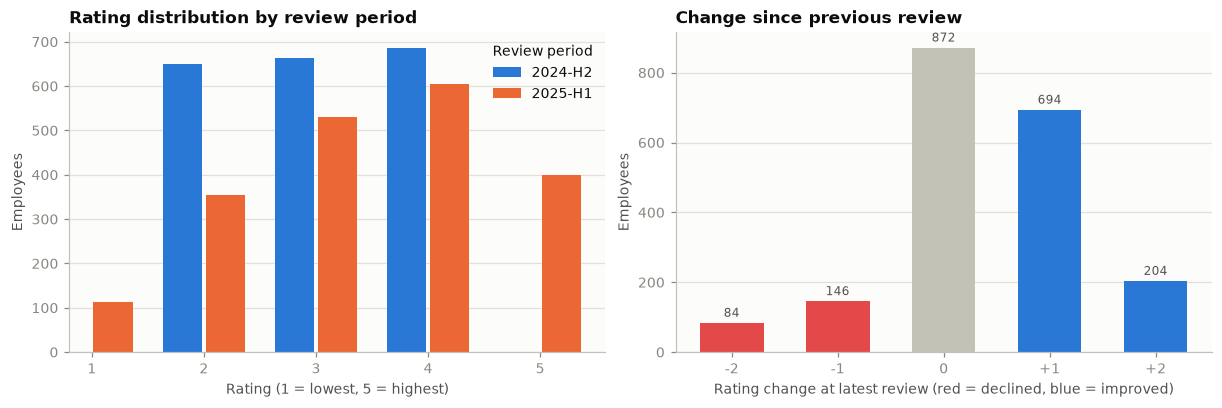

Average rating moved from **3.02** (2024-H2) to **3.41** (2025-H1). The share of top ratings (4–5) went from 34% to 50%. 84 employees dropped two or more points — they feed the attrition analysis (Q5).

review_period,2024-H2,2025-H1,change vs previous
rating,,,
1,<NA>,112,<NA>
2,650,354,-296
3,663,530,-133
4,687,605,-82
5,<NA>,399,<NA>


In [4]:
periods = sorted(hist["review_period"].unique())
dist = (hist.pivot_table(index="rating", columns="review_period", values="employee_id", aggfunc="count")
            .reindex(range(1, 6), fill_value=0))
changes = change.astype(int).value_counts().sort_index()

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6), layout="constrained")
x, width = np.arange(1, 6), 0.38
for i, (period, color) in enumerate(zip(periods, [BLUE, ORANGE])):
    left.bar(x + (i - (len(periods) - 1) / 2) * width, dist[period].to_numpy(float), width * 0.92,
             color=color, label=period)
left.set(xticks=x, xlabel="Rating (1 = lowest, 5 = highest)", ylabel="Employees",
         title="Rating distribution by review period")
left.legend(title="Review period")
left.grid(axis="x", visible=False)

colors = [DECLINE if c < 0 else IMPROVE if c > 0 else NO_CHANGE for c in changes.index]
bars = right.bar(changes.index, changes.to_numpy(float), 0.6, color=colors)
right.bar_label(bars, labels=[f"{v:,}" for v in changes], padding=2, color=INK2, fontsize=8)
right.set(xticks=changes.index, xticklabels=[f"{c:+d}" if c else "0" for c in changes.index],
          xlabel="Rating change at latest review (red = declined, blue = improved)", ylabel="Employees",
          title="Change since previous review")
right.grid(axis="x", visible=False)
plt.show()

means = hist.groupby("review_period")["rating"].mean()
say(f"Average rating moved from **{means.iloc[0]:.2f}** ({means.index[0]}) to **{means.iloc[-1]:.2f}** "
    f"({means.index[-1]}). The share of top ratings (4–5) went from "
    f"{pct((hist[hist.review_period == periods[0]].rating >= 4).mean())} to "
    f"{pct((hist[hist.review_period == periods[-1]].rating >= 4).mean())}. "
    f"{int((change <= -2).sum())} employees dropped two or more points — they feed the attrition analysis (Q5).")
dist.assign(**{"change vs previous": dist[periods[-1]] - dist[periods[0]]}) if len(periods) > 1 else dist

## 2. Critical skill gaps

**Definition.** For every employee and competency we compare the assessed proficiency with the level the role
requires: *gap = required − proficiency*. A gap of **2 or more levels** is **critical**; 1 level is *below*;
0 *meets*; negative *exceeds*. (`CRITICAL_GAP_LEVELS = 2` in `job.py`.)

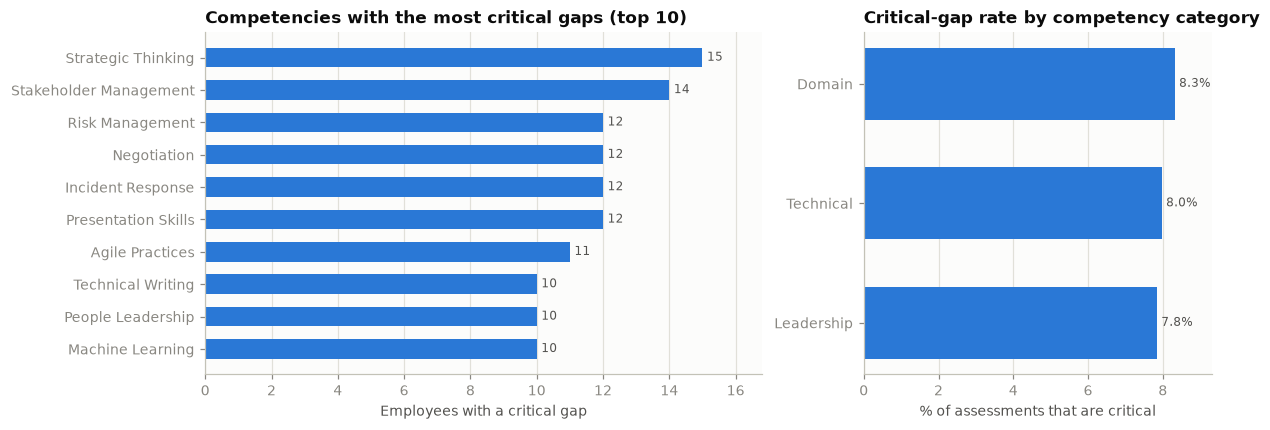

**325 critical gaps** across **317 employees** (16% of those assessed); 8 employees have more than one. The rate is similar across categories (7.8%–8.3%), so gaps are spread across skill types rather than concentrated. By department, **Sales** has the most critical gaps per 100 employees (21.2) and **Customer Support** the fewest (12.0).

Employees with the largest critical gaps (first 15):


,full_name,job_level,team_name,department,competency_name,proficiency_level,required_level,gap_levels
0,Kristie Heath,Director,Team LightYellow-1,Sales,Strategic Thinking,2,4,2
1,Douglas Salinas,Director,Team DeepPink-3,Design,Data Privacy,2,4,2
2,Lindsey Harris,IC1,Team DeepPink-3,Design,People Leadership,2,4,2
3,Kelly Smith,Senior IC,Team LightGray-4,Sales,Agile Practices,2,4,2
4,Christine Roberts,Senior Manager,Team LightGray-4,Sales,Decision Making,2,4,2
5,Cody Scott,IC3,Team LightGray-4,Sales,Strategic Thinking,2,4,2
6,Amanda Jackson,Senior Manager,Team SlateBlue-6,Customer Support,Technical Writing,2,4,2
7,Ryan Baker,Director,Team DarkMagenta-7,Finance,Project Management,2,4,2
8,Lisa Smith,IC2,Team Black-8,Product,Time Management,2,4,2
9,Sarah Young,IC3,Team Black-8,Product,Stakeholder Management,2,4,2


In [5]:
top = crit["competency_name"].value_counts().head(10).sort_values()
category = (gaps.groupby("category")
                .agg(assessments=("employee_id", "size"), critical_gaps=("is_critical_gap", "sum"))
                .assign(critical_rate=lambda d: d["critical_gaps"] / d["assessments"])
                .sort_values("critical_rate"))

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained", width_ratios=[1.6, 1])
hbar(left, top.index, top.values)
left.set(title="Competencies with the most critical gaps (top 10)", xlabel="Employees with a critical gap")
hbar(right, category.index, category["critical_rate"] * 100, fmt="{:.1f}%")
right.set(title="Critical-gap rate by competency category", xlabel="% of assessments that are critical")
plt.show()

dept = (gaps.groupby("department").agg(employees=("employee_id", "nunique"), critical=("is_critical_gap", "sum"))
            .assign(per_100=lambda d: 100 * d["critical"] / d["employees"]).sort_values("per_100", ascending=False))
two_plus = (crit.groupby("employee_id").size() >= 2).sum()
say(f"**{len(crit):,} critical gaps** across **{crit['employee_id'].nunique():,} employees** "
    f"({pct(crit['employee_id'].nunique() / gaps['employee_id'].nunique())} of those assessed); "
    f"{two_plus} employees have more than one. "
    + (f"The rate is similar across categories ({pct(category['critical_rate'].min(), 1)}–"
       f"{pct(category['critical_rate'].max(), 1)}), so gaps are spread across skill types rather than concentrated. "
       if category['critical_rate'].max() - category['critical_rate'].min() < 0.02 else
       f"**{category['critical_rate'].idxmax()}** competencies have the highest critical-gap rate "
       f"({pct(category['critical_rate'].max(), 1)}). ")
    + f"By department, **{dept.index[0]}** has the most "
    f"critical gaps per 100 employees ({dept['per_100'].iloc[0]:.1f}) and **{dept.index[-1]}** the fewest "
    f"({dept['per_100'].iloc[-1]:.1f}).")
print("Employees with the largest critical gaps (first 15):")
(crit.sort_values(["gap_levels", "required_level"], ascending=False)
     [["full_name", "job_level", "team_name", "department", "competency_name", "proficiency_level", "required_level", "gap_levels"]]
     .head(15).reset_index(drop=True))

## 3. High-potential employees ready for promotion

**Definition** (from the HR talent review, combined with the latest performance rating):

| Tier | Rule |
|---|---|
| **Ready — strong** | potential *High* + readiness *Ready Now* + latest rating **4 or 5** |
| **Ready** | potential *High* + readiness *Ready Now* |
| **Pipeline** | potential *High* + readiness *1–2 Years* (succession bench) |
| **Not ready** | everyone else |

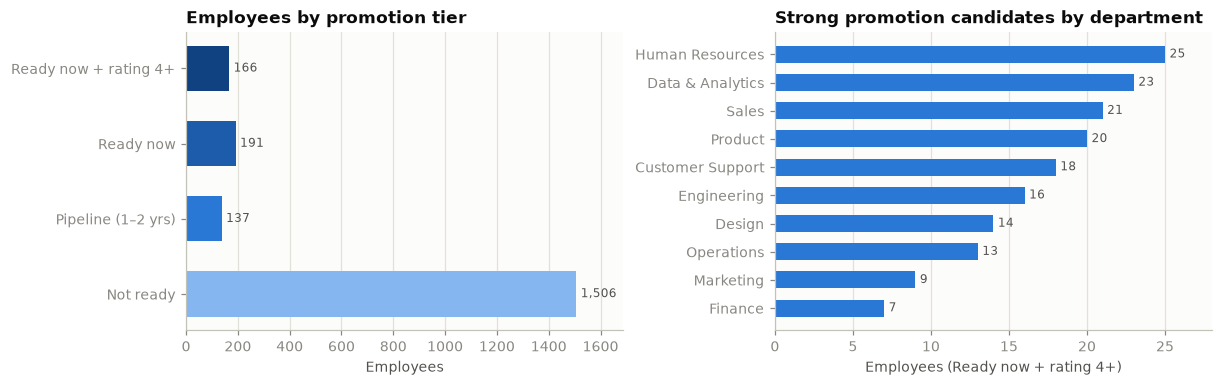

**166 strong candidates** and 191 more who are ready but rated below 4 at their latest review. **Human Resources** has the most strong candidates (25). **34 strong candidates have a critical skill gap** — a development action before promotion would de-risk those moves. The 137 *pipeline* employees are the succession bench for the next 1–2 years.

Strong candidates (first 15, highest-rated first):


,full_name,job_level,team_name,department,tenure_years,latest_rating,critical_gap_count,attrition_risk
0,Kathryn Obrien,Senior IC,Team MediumBlue-30,Design,7.6,5,1,Low
1,Tasha Lopez,IC2,Team CornflowerBlue-95,Human Resources,7.6,5,0,Low
2,Heather Bowman,IC2,Team Cornsilk-15,Engineering,7.5,5,0,Medium
3,Patrick Graham,IC2,Team MistyRose-32,Human Resources,7.5,5,0,Low
4,Javier Stephenson,Senior Manager,Team Yellow-23,Sales,7.4,5,1,Low
5,Dakota Mendez,Director,Team LightPink-56,Engineering,7.3,5,0,Low
6,Thomas Walker,IC2,Team Fuchsia-68,Human Resources,7.0,5,0,Low
7,Cynthia Tran,IC3,Team GoldenRod-22,Product,6.7,5,0,Medium
8,Christine Davis,Director,Team LightSteelBlue-84,Design,6.7,5,0,Low
9,Brittany Tran,Director,Team Yellow-23,Sales,6.5,5,1,Low


In [6]:
order = ["not_ready", "pipeline", "ready", "ready_strong"]
names = {"not_ready": "Not ready", "pipeline": "Pipeline (1–2 yrs)", "ready": "Ready now",
         "ready_strong": "Ready now + rating 4+"}
counts = promo["promotion_tier"].value_counts().reindex(order, fill_value=0)
by_dept = strong["department"].value_counts().sort_values()

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.4), layout="constrained")
hbar(left, [names[t] for t in order], counts.values, color=[RAMP[0], RAMP[2], RAMP[3], RAMP[4]])
left.set(title="Employees by promotion tier", xlabel="Employees")
hbar(right, by_dept.index, by_dept.values)
right.set(title="Strong promotion candidates by department", xlabel="Employees (Ready now + rating 4+)")
plt.show()

gapped = strong[strong["critical_gap_count"] > 0]
say(f"**{len(strong)} strong candidates** and {counts['ready']} more who are ready but rated below 4 at their latest "
    f"review. **{by_dept.index[-1]}** has the most strong candidates ({by_dept.iloc[-1]}). "
    f"**{len(gapped)} strong candidates have a critical skill gap** — a development action before promotion would "
    f"de-risk those moves. The {counts['pipeline']} *pipeline* employees are the succession bench for the next 1–2 years.")
print("Strong candidates (first 15, highest-rated first):")
(strong.sort_values(["latest_rating", "tenure_years"], ascending=False)
       [["full_name", "job_level", "team_name", "department", "tenure_years", "latest_rating", "critical_gap_count", "attrition_risk"]]
       .head(15).reset_index(drop=True))

## 4. Training and development activity

**Definition.** Learning events (enrollments, modules, quizzes, course completions, certifications) per employee,
plus the list of courses each employee completed. Look up an individual in section 8.

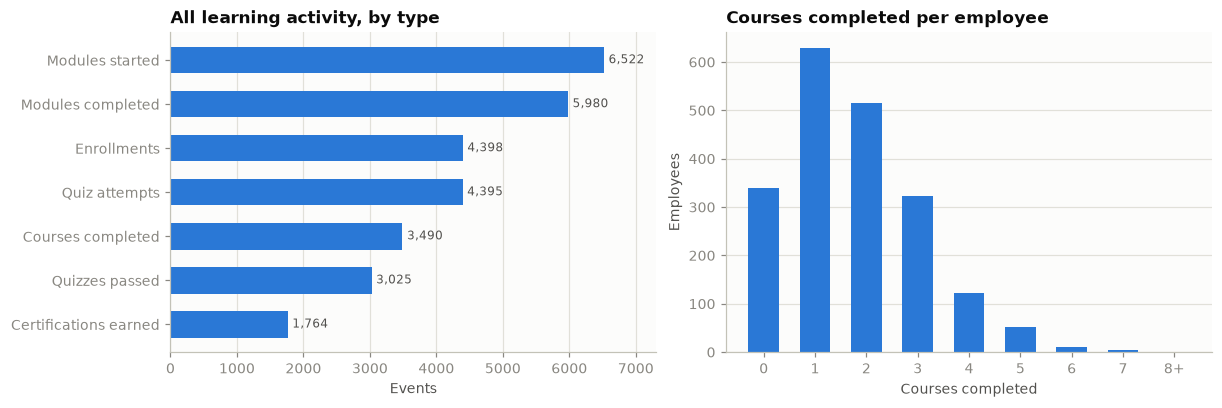

Employees completed a median of **2 courses** (2 distinct); **339 employees completed none**. 1,764 certifications were earned; 58% of employees hold at least one. Average quiz score: 66.9. 84% of employees were active in the last 180 days. Completions per employee range from 1.56 (**Customer Support**) to 1.89 (**Finance**).

Most active learners (first 10):


,full_name,department,courses_completed,certifications_earned,avg_quiz_score,completed_courses
0,Mark Castillo,Product,8,0,31.5,Cloud Architecture Fundamentals; Dimensional D...
1,Bryan Ware,Sales,7,3,35.7,Dimensional Data Modeling; Effective Decision ...
2,Robert Hayes,Operations,7,0,78.5,API Design Best Practices; Foundations of Peop...
3,Kristen Johnson,Data & Analytics,7,0,69.0,Agile Practices Certification; Cloud Architect...
4,Stephanie Barker,Human Resources,7,0,43.0,Applied Machine Learning; Building High-Perfor...
5,Alexis Taylor,Data & Analytics,6,3,70.8,Foundations of People Leadership; Market Analy...
6,Joshua James,Finance,6,2,56.5,Agile Practices Certification; Applied Machine...
7,Gary Hale,Customer Support,6,1,70.0,Cross-functional Collaboration; Public Speakin...
8,Jeremy Warren,Engineering,6,1,84.0,Applied Machine Learning; Business Communicati...
9,Cynthia Tran,Product,6,1,70.0,Agile Practices Certification; Distributed Sys...


In [7]:
activity_cols = {"enrollments": "Enrollments", "modules_started": "Modules started",
                 "modules_completed": "Modules completed", "quiz_attempts": "Quiz attempts",
                 "quizzes_passed": "Quizzes passed", "courses_completed": "Courses completed",
                 "certifications_earned": "Certifications earned"}
totals = learn[list(activity_cols)].sum().rename(activity_cols).sort_values()
completed = learn["courses_completed"].clip(upper=8).value_counts().sort_index()

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6), layout="constrained")
hbar(left, totals.index, totals.values)
left.set(title="All learning activity, by type", xlabel="Events")
bars = right.bar(completed.index, completed.to_numpy(float), 0.6, color=BLUE)
right.set(xticks=completed.index, xticklabels=[str(i) if i < 8 else "8+" for i in completed.index],
          title="Courses completed per employee", xlabel="Courses completed", ylabel="Employees")
right.grid(axis="x", visible=False)
plt.show()

top_dept = learn.groupby("department")["courses_completed"].mean().sort_values()
recent_col = [c for c in learn.columns if c.startswith("events_last_")][0]
say(f"Employees completed a median of **{learn['courses_completed'].median():.0f} courses** "
    f"({learn['distinct_courses_completed'].median():.0f} distinct); "
    f"**{int((learn['courses_completed'] == 0).sum())} employees completed none**. "
    f"{int(learn['certifications_earned'].sum()):,} certifications were earned; "
    f"{pct((learn['certifications_earned'] > 0).mean())} of employees hold at least one. "
    f"Average quiz score: {learn['avg_quiz_score'].astype(float).mean():.1f}. "
    f"{pct((learn[recent_col] > 0).mean())} of employees were active in the last "
    f"{recent_col.split('_')[-1].rstrip('d')} days. "
    f"Completions per employee range from {top_dept.iloc[0]:.2f} (**{top_dept.index[0]}**) "
    f"to {top_dept.iloc[-1]:.2f} (**{top_dept.index[-1]}**).")
print("Most active learners (first 10):")
(learn.sort_values(["courses_completed", "certifications_earned"], ascending=False)
      [["full_name", "department", "courses_completed", "certifications_earned", "avg_quiz_score", "completed_courses"]]
      .head(10).reset_index(drop=True))

**Caveat.** We report activity counts, not a course *completion rate*: in this data most course completions
have no matching enrollment event, so a funnel ratio (completions ÷ enrollments) would be misleading.
See *Limitations*.

## 5. Attrition risk from performance trends

**Definition.** Two independent signals per employee:

- **HR attrition risk** — the label from the talent review (Low / Medium / High).
- **Performance risk** — from the rating trend: fell 2+ levels → *High*, fell 1 → *Medium*, flat or up → *Low*
  (*Unknown* with fewer than two reviews).

**Combined risk** is the higher of the two. **Hidden risk** = HR says *Low* but performance risk is *High* —
the people most likely to be missed.

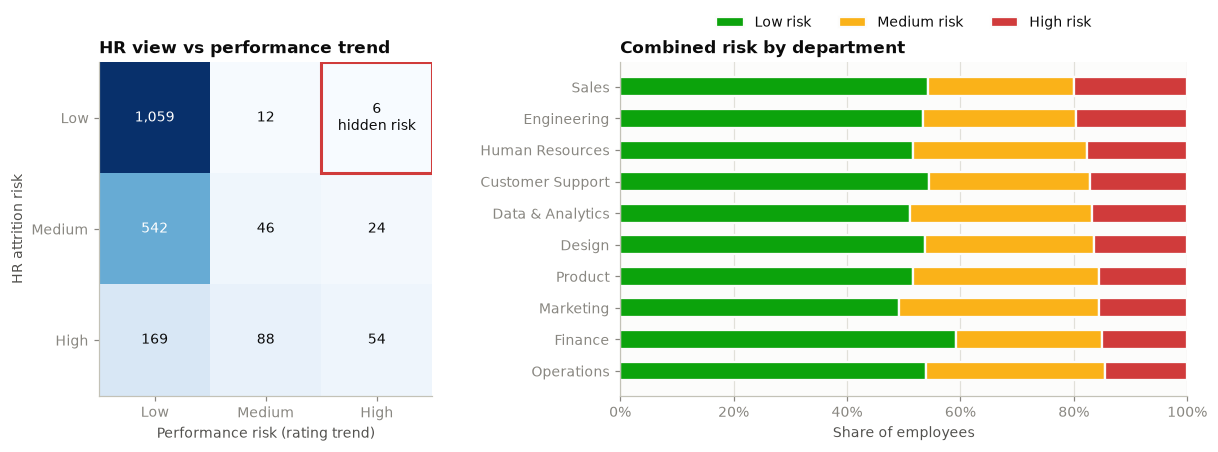

**341 employees (17%) are high risk** on at least one signal. The two signals agree for 1,159 employees; HR's label is the higher one for 799 and the performance trend for 42. Of the 84 employees whose rating fell by 2+ levels, 64% are already flagged High by HR — the trend and HR's judgement largely agree. **6 employees are hidden risks** (below). **Sales** has the highest share of high-risk employees (20%).

Hidden risk — HR says Low, performance falling sharply:


,full_name,job_level,team_name,department,previous_rating,latest_rating,hr_attrition_risk,performance_risk,events_last_180d
0,Debra Davis,IC3,Team DarkGreen-26,Human Resources,3,1,Low,High,3
1,Michael Cooper,Manager,Team Moccasin-40,Finance,3,1,Low,High,0
2,Roberto Jackson,IC2,Team Beige-51,Sales,4,2,Low,High,4
3,James Mendoza,IC2,Team MediumSlateBlue-57,Operations,4,2,Low,High,0
4,Gary Newton,IC3,Team Wheat-76,Data & Analytics,3,1,Low,High,2
5,Crystal White,Senior IC,Team LightSlateGray-100,Human Resources,3,1,Low,High,2


In [8]:
levels = ["Low", "Medium", "High"]
grid = pd.crosstab(risk["hr_attrition_risk"], risk["performance_risk"]).reindex(index=levels, columns=levels, fill_value=0)
dept_risk = (pd.crosstab(risk["department"], risk["combined_risk"], normalize="index")
               .reindex(columns=levels, fill_value=0).sort_values("High"))

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained", width_ratios=[1, 1.4])
image = left.imshow(grid.to_numpy(float), cmap="Blues")
left.set(xticks=range(3), xticklabels=levels, yticks=range(3), yticklabels=levels,
         xlabel="Performance risk (rating trend)", ylabel="HR attrition risk", title="HR view vs performance trend")
left.grid(False)
peak = grid.to_numpy().max()
for (i, j), value in np.ndenumerate(grid.to_numpy()):
    label = f"{value:,}" + ("\nhidden risk" if (i, j) == (0, 2) else "")
    left.text(j, i, label, ha="center", va="center", fontsize=9, color="white" if value > peak * 0.5 else INK)
left.add_patch(Rectangle((1.5, -0.5), 1, 1, fill=False, edgecolor=RISK["High"], linewidth=2))

y = np.arange(len(dept_risk))
start = np.zeros(len(dept_risk))
for level in levels:
    right.barh(y, dept_risk[level].to_numpy(float), left=start, height=0.6, color=RISK[level],
               edgecolor=SURFACE, linewidth=1.5, label=f"{level} risk")
    start += dept_risk[level].to_numpy(float)
right.set(yticks=y, yticklabels=dept_risk.index, xlim=(0, 1), title="Combined risk by department",
          xlabel="Share of employees")
right.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
right.grid(axis="y", visible=False)
right.legend(ncols=3, loc="lower center", bbox_to_anchor=(0.5, 1.06))
plt.show()

hidden = risk[risk["hidden_risk"]]
aligned = risk["risk_alignment"].value_counts()
say(f"**{int((risk['combined_risk'] == 'High').sum()):,} employees ({pct((risk['combined_risk'] == 'High').mean())}) are high "
    f"risk** on at least one signal. The two signals agree for {aligned.get('aligned', 0):,} employees; HR's label is the "
    f"higher one for {aligned.get('hr_higher', 0):,} and the performance trend for {aligned.get('performance_higher', 0):,}. "
    f"Of the {int((risk['performance_risk'] == 'High').sum())} employees whose rating fell by 2+ levels, "
    f"{pct((risk[risk.performance_risk == 'High'].hr_attrition_risk == 'High').mean())} are already flagged High by HR — "
    f"the trend and HR's judgement largely agree. **{len(hidden)} employees are hidden risks** (below). "
    f"**{dept_risk.index[-1]}** has the highest share of high-risk employees ({pct(dept_risk['High'].iloc[-1])}).")
print("Hidden risk — HR says Low, performance falling sharply:")
(hidden[["full_name", "job_level", "team_name", "department", "previous_rating", "latest_rating", "hr_attrition_risk",
         "performance_risk", recent_col]].reset_index(drop=True))

## 6. Performance vs team and project outcomes

**Definition.** One point per team that has at least one project: the team's average *latest* rating against the
average *outcome score* of its projects. We measure the linear relationship with the correlation coefficient *r*
(−1 to +1) and test whether it could be chance with a **permutation test**: shuffle the outcome scores across
teams 10,000 times and count how often a shuffled correlation is at least as strong as the real one.

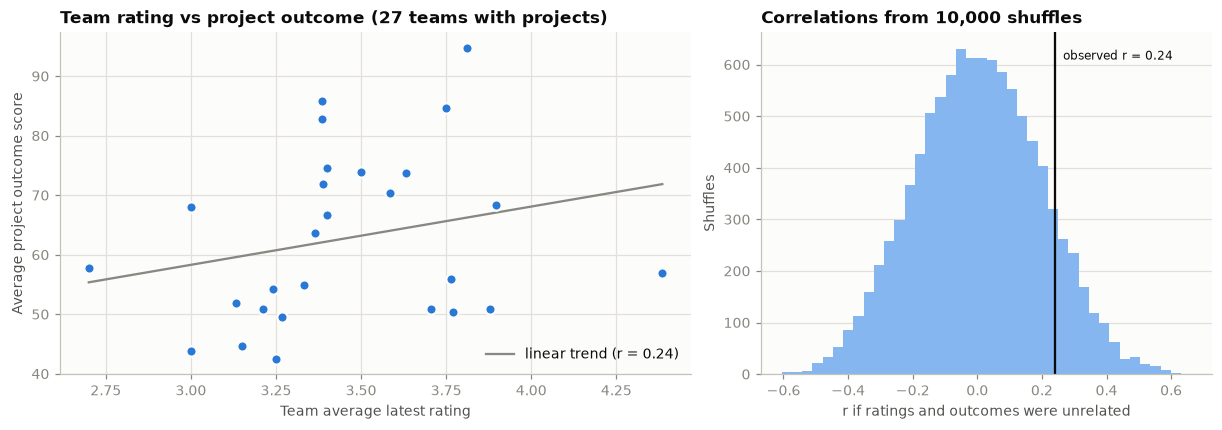

The correlation is **r = 0.24**: teams with higher ratings tend to have slightly better project outcomes. But a correlation this strong or stronger appears in **22% of random shuffles** (p = 0.22), so with only 27 teams it is not distinguishable from chance. **We cannot conclude that team performance and project outcomes are linked.** 73 of 100 teams have no projects at all and cannot be assessed. Correlation would not show causation even if it were significant.

,team_name,department,headcount,avg_latest_rating,high_performer_rate,project_count,avg_project_outcome_score,on_time_rate
0,Team YellowGreen-89,Human Resources,21,3.81,0.619,1,94.76,1.0
1,Team Moccasin-13,Customer Support,26,3.385,0.538,1,85.79,1.0
2,Team GreenYellow-34,Operations,12,3.75,0.667,1,84.68,1.0
3,Team BlanchedAlmond-87,Operations,13,3.385,0.462,1,82.88,1.0
4,Team SlateBlue-6,Customer Support,20,3.4,0.5,1,74.61,1.0
5,Team BurlyWood-43,Data & Analytics,22,3.5,0.5,1,73.89,1.0
6,Team HoneyDew-9,Engineering,19,3.632,0.526,1,73.67,1.0
7,Team Cornsilk-15,Engineering,18,3.389,0.444,1,71.9,1.0
8,Team Black-8,Product,29,3.586,0.517,1,70.33,1.0
9,Team Olive-38,Data & Analytics,19,3.895,0.632,2,68.315,0.5


In [9]:
x = with_projects["avg_latest_rating"].to_numpy(float)
y = with_projects["avg_project_outcome_score"].to_numpy(float)
rng = np.random.default_rng(42)                      # fixed seed: the same answer on every run
null = np.array([np.corrcoef(x, rng.permutation(y))[0, 1] for _ in range(10_000)])
p_value = (np.abs(null) >= abs(r)).mean()

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained", width_ratios=[1.4, 1])
left.scatter(x, y, s=46, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=3)
slope, intercept = np.polyfit(x, y, 1)
xs = np.linspace(x.min(), x.max(), 50)
left.plot(xs, slope * xs + intercept, color=MUTED, linewidth=1.5, label=f"linear trend (r = {r:.2f})")
left.set(title=f"Team rating vs project outcome ({len(x)} teams with projects)",
         xlabel="Team average latest rating", ylabel="Average project outcome score")
left.legend(loc="lower right")

right.hist(null, bins=40, color=RAMP[0])
right.axvline(r, color=INK, linewidth=1.5)
right.text(r, right.get_ylim()[1] * 0.92, f"  observed r = {r:.2f}", color=INK, fontsize=8)
right.set(title="Correlations from 10,000 shuffles", xlabel="r if ratings and outcomes were unrelated",
          ylabel="Shuffles")
right.grid(axis="x", visible=False)
plt.show()

status_cols = [c for c in with_projects.columns if c.startswith("projects_")]
say(f"The correlation is **r = {r:.2f}**: teams with higher ratings tend to have slightly better project outcomes. "
    f"But a correlation this strong or stronger appears in **{pct(p_value)} of random shuffles** (p = {p_value:.2f}), "
    f"so with only {len(x)} teams it is {'not ' if p_value >= 0.05 else ''}distinguishable from chance. "
    f"{'**We cannot conclude that team performance and project outcomes are linked.** ' if p_value >= 0.05 else ''}"
    f"{len(teams) - len(with_projects)} of {len(teams)} teams have no projects at all and cannot be assessed. "
    f"Correlation would not show causation even if it were significant.")
(with_projects[["team_name", "department", "headcount", "avg_latest_rating", "high_performer_rate", "project_count",
                "avg_project_outcome_score", "on_time_rate"]]
     .sort_values("avg_project_outcome_score", ascending=False).reset_index(drop=True))

## 7. Distribution of skills across the organization

**Definition.** Assessed proficiency levels (1–5) by competency category and department. Organisation-wide figures
are re-aggregated from the per-level head-counts, so departments of different sizes are weighted correctly.

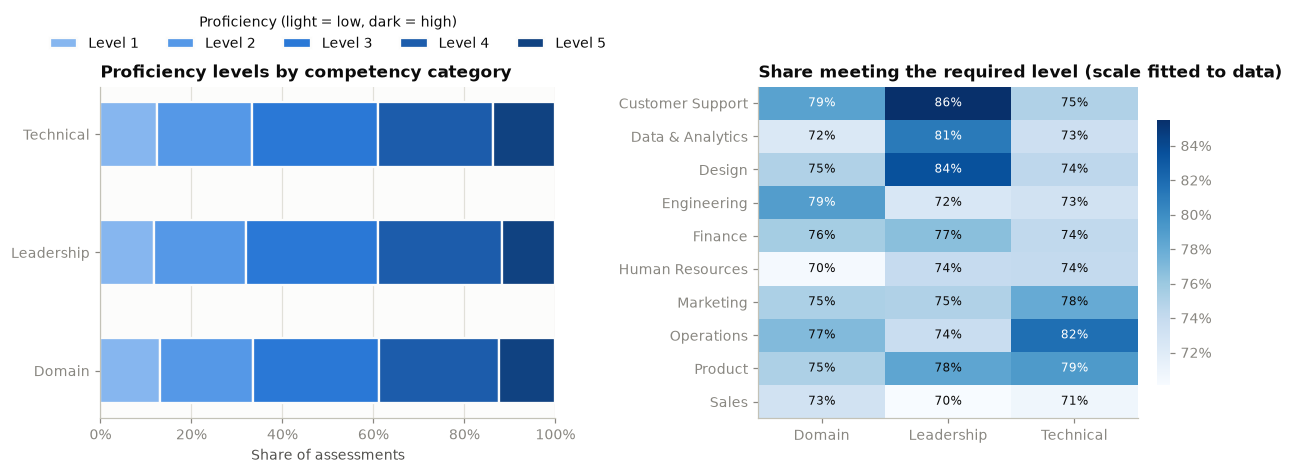

Average proficiency: **Domain** 3.05, **Leadership** 3.07, **Technical** 3.07. Overall 75% of assessments meet the required level. Weakest competency: **Stakeholder Management** (65% meeting); strongest: **Vendor Management** (82%). Department × category coverage ranges from 70% to 86%.

Competencies with the lowest share meeting the requirement (organisation-wide):


,competency_name,category,meeting_requirement,assessed,meeting_rate
0,Stakeholder Management,Domain,60.0,92,0.652174
1,Customer Empathy,Domain,60.0,88,0.681818
2,Presentation Skills,Domain,73.0,105,0.695238
3,Incident Response,Technical,73.0,105,0.695238
4,Conflict Resolution,Leadership,65.0,93,0.698925
5,Negotiation,Domain,72.0,103,0.699029
6,Forecasting,Domain,73.0,104,0.701923
7,Risk Management,Domain,66.0,94,0.702128
8,Security Fundamentals,Technical,65.0,92,0.706522
9,Communication,Domain,65.0,91,0.714286


In [10]:
level_cols = [f"proficiency_level_{i}" for i in range(1, 6)]
by_cat = skills.groupby("category")[level_cols].sum()
shares = by_cat.div(by_cat.sum(axis=1), axis=0)
skills = skills.assign(meeting=lambda d: (d["meeting_requirement_rate"].astype(float) * d["employees_assessed"]).round())
heat = (skills.groupby(["department", "category"])[["meeting", "employees_assessed"]].sum()
              .pipe(lambda d: d["meeting"] / d["employees_assessed"]).unstack())

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained", width_ratios=[1.2, 1])
y, start = np.arange(len(shares)), np.zeros(len(shares))
for i, col in enumerate(level_cols):
    left.barh(y, shares[col].to_numpy(float), left=start, height=0.55, color=RAMP[i], edgecolor=SURFACE,
              linewidth=1.5, label=f"Level {i + 1}")
    start += shares[col].to_numpy(float)
left.set(yticks=y, yticklabels=shares.index, xlim=(0, 1), title="Proficiency levels by competency category",
         xlabel="Share of assessments")
left.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
left.grid(axis="y", visible=False)
left.legend(ncols=5, loc="lower center", bbox_to_anchor=(0.5, 1.07), title="Proficiency (light = low, dark = high)")

low, high = np.nanmin(heat.to_numpy()), np.nanmax(heat.to_numpy())
image = right.imshow(heat.to_numpy(float), cmap="Blues", aspect="auto", vmin=low, vmax=high)
bar = fig.colorbar(image, ax=right, shrink=0.8, format=lambda v, _: f"{v:.0%}")
bar.outline.set_visible(False)
right.set(xticks=range(heat.shape[1]), xticklabels=heat.columns, yticks=range(heat.shape[0]),
          yticklabels=heat.index, title="Share meeting the required level (scale fitted to data)")
right.grid(False)
for (i, j), value in np.ndenumerate(heat.to_numpy(float)):
    right.text(j, i, f"{value:.0%}", ha="center", va="center", fontsize=8,
               color="white" if (value - low) / (high - low) > 0.55 else INK)
plt.show()

org = skills.groupby(["competency_name", "category"])[["meeting", "employees_assessed"]].sum()
org = org.assign(meeting_rate=org["meeting"] / org["employees_assessed"]).sort_values("meeting_rate")
avg_level = (by_cat * range(1, 6)).sum(axis=1) / by_cat.sum(axis=1)
say(f"Average proficiency: " + ", ".join(f"**{c}** {v:.2f}" for c, v in avg_level.items()) + ". "
    f"Overall {pct(meeting)} of assessments meet the required level. Weakest competency: "
    f"**{org.index[0][0]}** ({pct(org['meeting_rate'].iloc[0])} meeting); strongest: "
    f"**{org.index[-1][0]}** ({pct(org['meeting_rate'].iloc[-1])}). Department × category coverage ranges from "
    f"{pct(np.nanmin(heat.to_numpy()))} to {pct(np.nanmax(heat.to_numpy()))}.")
print("Competencies with the lowest share meeting the requirement (organisation-wide):")
org.head(10).reset_index().rename(columns={"meeting": "meeting_requirement", "employees_assessed": "assessed"})

## 8. Look up one employee

Q1 and Q4 ask about *each* employee. This cell shows one person's full picture across all Gold tables:
review history, promotion tier, attrition risk, skill assessments and learning.

**How to use it**

1. In the cell below, find the two lines under **`EDIT HERE`** at the very top.
2. Either type an employee number after `EMPLOYEE_ID =` (for example `EMPLOYEE_ID = 1332`),
   **or**, if you only know the name, type part of it in quotes after `SEARCH_NAME =` (for example `SEARCH_NAME = "Davis"`)
   to list matching employees with their IDs.
3. Run the cell: click into it and press **Shift + Enter**.

The cell only needs the first **Setup** cell at the top to have run once (it loads the data); after that you can
look up as many people as you like by re-running just this cell.

With nothing entered (`EMPLOYEE_ID = None`, `SEARCH_NAME = ""`) it shows an example — the first *hidden risk*
employee from section 5.

In [11]:
# ============================ EDIT HERE ============================
EMPLOYEE_ID = None   # type an employee number, e.g. 1062   (None = show an example)
SEARCH_NAME = ""     # or part of a name, e.g. "Davis", to list matching employees and their IDs
# ================== nothing to change below this line ==================

# This cell only needs the FIRST cell under "Setup" (it loads the Gold tables), so after that has run
# once you can change the ID above and re-run just this cell.
if "gold" not in globals():
    raise RuntimeError("The data isn't loaded yet. Scroll to the top, run the first code cell under 'Setup' "
                       "(or use Run All once), then run this cell again.")

people, reviews_t, risk_t = gold["promotion_readiness"], gold["employee_performance_history"], gold["attrition_risk"]
skills_t, learning_t = gold["employee_skill_gaps"], gold["employee_learning_summary"]


def employee_profile(employee_id):
    who = people[people["employee_id"] == employee_id]
    if who.empty:
        ids = people["employee_id"]
        print(f"No employee with ID {employee_id}. IDs run from {ids.min()} to {ids.max()} - "
              f"or set SEARCH_NAME to find someone by name.")
        return
    p = who.iloc[0]
    display(Markdown(f"### {p['full_name']} — {p['job_level']}, {p['team_name']} ({p['department']}), "
                     f"hired {p['hire_date']} ({p['tenure_years']} years)"))
    print("Review history:")
    display(reviews_t[reviews_t["employee_id"] == employee_id][
        ["review_period", "rating", "previous_rating", "rating_change", "recorded_before_hire"]])
    print("Promotion & risk:")
    display(pd.DataFrame([{**p[["potential_rating", "promotion_readiness", "promotion_tier", "critical_gap_count"]].to_dict(),
                           **risk_t[risk_t["employee_id"] == employee_id][["hr_attrition_risk", "performance_risk",
                                                                          "combined_risk"]].iloc[0].to_dict()}]))
    print("Skill assessments:")
    display(skills_t[skills_t["employee_id"] == employee_id][["competency_name", "category", "proficiency_level",
                                                              "required_level", "gap_status", "recorded_before_hire"]])
    l = learning_t[learning_t["employee_id"] == employee_id].iloc[0]
    print(f"Learning: {l['total_events']} events ({l['events_before_hire']} before hire), "
          f"{l['courses_completed']} course completions, {l['certifications_earned']} certifications. "
          f"Completed: {l['completed_courses'] or '—'}")


if str(SEARCH_NAME).strip():
    term = str(SEARCH_NAME).strip()
    matches = people[people["full_name"].str.contains(term, case=False, regex=False, na=False)]
    print(f'{len(matches)} employee(s) matching "{term}". '
          f"Copy an employee_id into EMPLOYEE_ID above, clear SEARCH_NAME, and run again.")
    display(matches[["employee_id", "full_name", "job_level", "team_name", "department"]].head(25)
            .reset_index(drop=True))
    if len(matches) > 25:
        print("Showing the first 25 - type more of the name to narrow it down.")
elif EMPLOYEE_ID is None:
    hidden_ids = risk_t.loc[risk_t["hidden_risk"], "employee_id"]
    example = int(hidden_ids.iloc[0]) if len(hidden_ids) else int(people["employee_id"].iloc[0])
    display(Markdown(f"*No ID entered - showing an example: employee {example} (a hidden-risk employee from "
                     f"section 5). Type an ID in `EMPLOYEE_ID` above to look someone else up.*"))
    employee_profile(example)
else:
    employee_profile(int(EMPLOYEE_ID))

*No ID entered - showing an example: employee 492 (a hidden-risk employee from section 5). Type an ID in `EMPLOYEE_ID` above to look someone else up.*

### Debra Davis — IC3, Team DarkGreen-26 (Human Resources), hired 2023-12-27 (2.8 years)

Review history:


,review_period,rating,previous_rating,rating_change,recorded_before_hire
982,2024-H2,3,<NA>,<NA>,False
983,2025-H1,1,3,-2,False


Promotion & risk:


,potential_rating,promotion_readiness,promotion_tier,critical_gap_count,hr_attrition_risk,performance_risk,combined_risk
0,Medium,1-2 Years,not_ready,1,Low,High,High


Skill assessments:


,competency_name,category,proficiency_level,required_level,gap_status,recorded_before_hire
982,Risk Management,Domain,4,4,meets,False
983,Technical Writing,Domain,2,4,critical,False


Learning: 12 events (0 before hire), 2 course completions, 1 certifications. Completed: Data Privacy Fundamentals; Stakeholder Management Essentials


## 9. Data anomalies — records dated before the employee was hired

While checking the time span of the data we found records that pre-date the employee's own hire date:
reviews for half-years that **ended before** the person joined, skill assessments and learning activity from
before they started.

**How the pipeline treats them:** each record is **kept and flagged** (`recorded_before_hire`), never dropped.
The data cannot tell us which side is wrong — the record, or the hire date (which may really mean
*"joined current role"*). That is an open question for the HR data owner. Until it is answered, this section
shows how big the issue is, who it affects, and how much the key answers change if the flagged records are
excluded.

*Rule:* a review is flagged when its period **ended** before the hire date (someone hired mid-period worked part
of it and is not flagged); assessments and learning events are flagged when dated before the hire date.

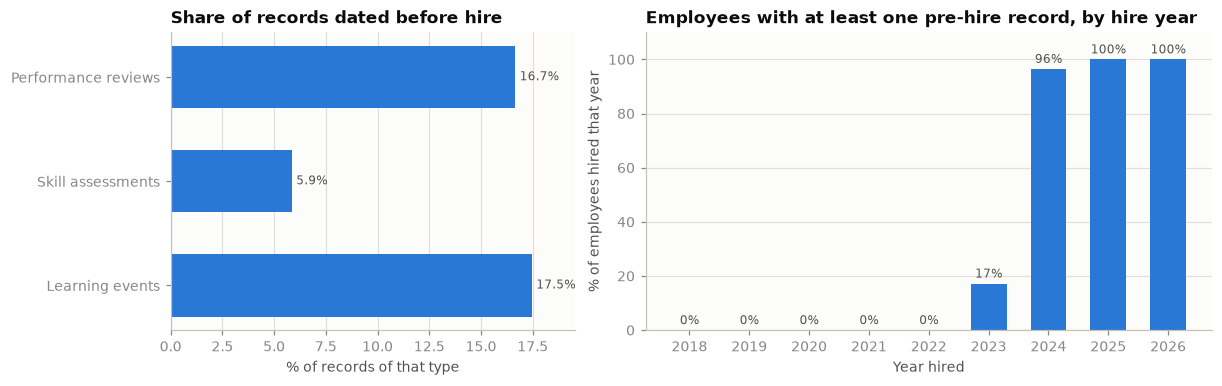

**660 employees (33%)** have at least one record dated before they were hired: 666 reviews (17%), 234 skill assessments and 5,161 learning events. The pattern is driven by hire date: 99% of employees hired since 2024 are affected, against 3% of earlier hires — consistent with review and learning histories that were recorded independently of when each person joined.

,record type,total,before hire,share
0,Performance reviews,4000,666,16.7%
1,Skill assessments,4000,234,5.9%
2,Learning events,29574,5161,17.5%


In [12]:
record_types = pd.DataFrame([
    {"record type": "Performance reviews", "total": len(hist), "before hire": int(hist["recorded_before_hire"].sum())},
    {"record type": "Skill assessments", "total": len(gaps), "before hire": int(gaps["recorded_before_hire"].sum())},
    {"record type": "Learning events", "total": int(learn["total_events"].sum()),
     "before hire": int(learn["events_before_hire"].sum())},
]).assign(share=lambda d: d["before hire"] / d["total"])

affected_ids = (set(hist.loc[hist["recorded_before_hire"], "employee_id"])
                | set(gaps.loc[gaps["recorded_before_hire"], "employee_id"])
                | set(learn.loc[learn["events_before_hire"] > 0, "employee_id"]))
people = promo[["employee_id", "hire_date"]].assign(
    hire_year=lambda d: pd.to_datetime(d["hire_date"].astype(str)).dt.year,
    affected=lambda d: d["employee_id"].isin(affected_ids))
by_year = people.groupby("hire_year")["affected"].mean()

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.4), layout="constrained", width_ratios=[1, 1.4])
hbar(left, record_types["record type"][::-1], (record_types["share"] * 100)[::-1], fmt="{:.1f}%")
left.set(title="Share of records dated before hire", xlabel="% of records of that type")
bars = right.bar(by_year.index.astype(str), by_year.to_numpy(float) * 100, 0.6, color=BLUE)
right.bar_label(bars, labels=[f"{v:.0%}" for v in by_year], padding=2, color=INK2, fontsize=8)
right.set(title="Employees with at least one pre-hire record, by hire year", xlabel="Year hired",
          ylabel="% of employees hired that year", ylim=(0, 110))
right.grid(axis="x", visible=False)
plt.show()

recent = people[people["hire_year"] >= 2024]
say(f"**{len(affected_ids):,} employees ({pct(len(affected_ids) / len(people))})** have at least one record dated before "
    f"they were hired: {record_types.loc[0, 'before hire']:,} reviews ({pct(record_types.loc[0, 'share'])}), "
    f"{record_types.loc[1, 'before hire']:,} skill assessments and {record_types.loc[2, 'before hire']:,} learning events. "
    f"The pattern is driven by hire date: {pct(recent['affected'].mean())} of employees hired since 2024 are affected, "
    f"against {pct(people[people.hire_year < 2024]['affected'].mean())} of earlier hires — consistent with review and "
    f"learning histories that were recorded independently of when each person joined.")
record_types.assign(share=lambda d: (100 * d["share"]).round(1).astype(str) + "%")

**How much do the answers depend on these records?** Each key figure below is shown as published (all records
kept) and with the flagged records excluded. Large differences mean that answer should be read with care until the
data owner confirms which date is right.

In [13]:
clean_hist = hist[~hist["recorded_before_hire"]]
latest_period = periods[-1]
strong_all = promo["promotion_tier"] == "ready_strong"
sensitivity = pd.DataFrame([
    ("Q1  Average rating, " + latest_period,
     hist.loc[hist.review_period == latest_period, "rating"].mean(),
     clean_hist.loc[clean_hist.review_period == latest_period, "rating"].mean()),
    ("Q2  Critical skill gaps", int(gaps["is_critical_gap"].sum()),
     int(gaps.loc[~gaps["recorded_before_hire"], "is_critical_gap"].sum())),
    ("Q3  Strong promotion candidates", int(strong_all.sum()),
     int((strong_all & ~promo["latest_review_before_hire"]).sum())),
    ("Q4  Learning events", int(learn["total_events"].sum()),
     int(learn["total_events"].sum() - learn["events_before_hire"].sum())),
    ("Q5  Performance risk High (rating fell 2+)", int((risk["performance_risk"] == "High").sum()),
     int(((risk["performance_risk"] == "High") & ~risk["trend_uses_pre_hire_review"]).sum())),
    ("Q5  Hidden risk", int(risk["hidden_risk"].sum()),
     int((risk["hidden_risk"] & ~risk["trend_uses_pre_hire_review"]).sum())),
], columns=["answer", "all records (published)", "excluding pre-hire records"])
sensitivity["change"] = (sensitivity["excluding pre-hire records"] / sensitivity["all records (published)"] - 1)
say(f"Excluding the flagged records changes the counts by between "
    f"{pct(sensitivity['change'].abs().min())} and {pct(sensitivity['change'].abs().max())}. "
    f"{int(risk['trend_uses_pre_hire_review'].sum())} employees' rating trends (Q5) rest on at least one "
    f"pre-hire review — those trends are the least reliable figures in this notebook.")
sensitivity.assign(**{c: sensitivity[c].map(lambda v: f"{v:,.2f}" if isinstance(v, float) and v % 1 else f"{v:,.0f}")
                      for c in ["all records (published)", "excluding pre-hire records"]},
                   change=sensitivity["change"].map(lambda v: f"{v:+.1%}"))

Excluding the flagged records changes the counts by between 0% and 21%. 396 employees' rating trends (Q5) rest on at least one pre-hire review — those trends are the least reliable figures in this notebook.

,answer,all records (published),excluding pre-hire records,change
0,"Q1 Average rating, 2025-H1",3.41,3.42,+0.2%
1,Q2 Critical skill gaps,325,307,-5.5%
2,Q3 Strong promotion candidates,166,148,-10.8%
3,Q4 Learning events,"29,574","24,413",-17.5%
4,Q5 Performance risk High (rating fell 2+),84,66,-21.4%
5,Q5 Hidden risk,6,6,+0.0%


In [14]:
worst = (hist.groupby("employee_id")["recorded_before_hire"].sum()
         .add(learn.set_index("employee_id")["events_before_hire"], fill_value=0).idxmax())
example = learn[learn["employee_id"] == worst].iloc[0]
say(f"**Example — {example['full_name']}** (employee {worst}): hired **{example['hire_date']}**, first learning activity "
    f"**{example['first_activity_date']}**, {int(example['events_before_hire'])} of {int(example['total_events'])} learning "
    f"events before hire.")
hist[hist["employee_id"] == worst][["review_period", "period_start", "rating", "submitted_date", "recorded_before_hire"]]

**Example — Brandy Davis** (employee 1062): hired **2026-05-13**, first learning activity **2023-09-21**, 23 of 24 learning events before hire.

,review_period,period_start,rating,submitted_date,recorded_before_hire
2122,2024-H2,2024-07-01,4,2025-08-30,True
2123,2025-H1,2025-01-01,5,2026-02-15,True


## 10. Data quality and lineage — can these numbers be trusted?

Every figure above comes from Gold, which the pipeline only publishes after validation (unique grain, no dropped
employees, totals that reconcile with Silver). Records that failed validation were **quarantined**, not silently
dropped. Full column-level mapping: `data/talent-pipeline/LINEAGE.md`; test evidence: `TESTING.md`.

In [15]:
steps = pd.DataFrame([{"step": s["name"], "status": s["status"], "duration_s": s["duration_s"]}
                      for s in manifest["steps"]])
silver = next(s for s in manifest["steps"] if s["name"] == "silver")["metrics"]
entities = sorted(k[:-5] for k in silver if k.endswith("_read")
                  and all(f"{k[:-5]}_{m}" in silver for m in ("valid", "quarantined")))
quality = pd.DataFrame([{"entity": e, "read": silver[f"{e}_read"], "valid": silver[f"{e}_valid"],
                         "quarantined": silver[f"{e}_quarantined"]} for e in entities])
quality["quarantined_%"] = (100 * quality["quarantined"] / quality["read"]).round(2)
say(f"Latest complete run `{manifest['run_id']}`: **{manifest['status']}**, code `{manifest['code']['sha256'][:12]}…`, "
    f"Python {manifest['code']['python']}, pandas {manifest['code']['packages']['pandas']}.")
display(steps)
bronze = next((s["metrics"] for s in manifest["steps"] if s["name"] == "bronze"), {})
empty_files = bronze.get("learning_files_empty", 0)
say(f"**Source files:** {bronze.get('learning_files_listed', 0):,} learning-activity files received, "
    f"**{empty_files} empty (0 bytes)**" + (" — a day with no events at all usually means a failed or partial "
    "delivery from the source system; the run log names the file(s)." if empty_files else ".")
    + " Records rejected during cleaning are quarantined (below), not silently dropped.")
display(quality)
inputs = pd.DataFrame([{"gold table": k.split("/", 1)[1], "built from": ", ".join(v)}
                       for k, v in manifest["lineage"].items() if k.startswith("gold/")])
inputs

Latest complete run `20261015T073658Z-510cfba1`: **succeeded**, code `873f62af0b51…`, Python 3.13.16, pandas 3.0.6.

,step,status,duration_s
0,preflight,succeeded,0.021
1,bronze,succeeded,0.521
2,silver,succeeded,3.930
3,gold,succeeded,1.128


**Source files:** 783 learning-activity files received, **1 empty (0 bytes)** — a day with no events at all usually means a failed or partial delivery from the source system; the run log names the file(s). Records rejected during cleaning are quarantined (below), not silently dropped.

,entity,read,valid,quarantined,quarantined_%
0,competencies,40,40,0,0.00
1,competency_assessments,4000,4000,0,0.00
2,employees,2000,2000,0,0.00
3,learning_events,29868,29574,294,0.98
4,performance_reviews,4000,4000,0,0.00
5,projects,33,33,0,0.00
6,talent_review,2000,2000,0,0.00
7,teams,100,100,0,0.00


,gold table,built from
0,employee_performance_history,"silver/performance_reviews, silver/dim_employee"
1,employee_skill_gaps,"silver/competency_assessments, silver/competen..."
2,promotion_readiness,"silver/dim_employee, silver/talent_review, gol..."
3,employee_learning_summary,"silver/learning_events, silver/dim_employee"
4,attrition_risk,"silver/dim_employee, silver/talent_review, gol..."
5,team_performance_outcomes,"silver/teams, silver/dim_employee, gold/employ..."
6,skill_distribution,gold/employee_skill_gaps


## 11. Limitations and assumptions

- **Synthetic data.** The dataset is generated for the workshop; patterns may not reflect a real organisation.
- **Different time spans per source.** Performance reviews cover only two half-years (2024-H2, 2025-H1) and the
  talent review a single cycle, while learning activity spans about three years and assessments one year. The rating
  "trend" is therefore a single change between two reviews — an early-warning signal, not a long-term trajectory.
- **Records dated before hire.** About a sixth of reviews and learning events pre-date the employee's hire date
  (section 9). They are kept and flagged pending confirmation from the HR data owner of what `hire_date` means.
- **Agreed definitions.** *Critical gap* (2+ levels), *strong* candidate (rating 4+), the risk mapping and the
  180-day "recent learning" window are business choices, kept as named constants in `job.py`; changing them
  changes the answers.
- **Learning funnel.** Completion events mostly lack matching enrollments, so we report counts, not completion
  rates.
- **Small project sample.** Few teams have projects, so the Q6 relationship cannot be established either way;
  correlation would not imply causation.
- **Quarantined records are excluded.** See section 9 for how many and why; they are kept in the lake for review.
- **Point in time.** Tenure and "recent" activity are measured at the run's as-of date shown at the top.